In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import plotly.graph_objects as go
from scipy import ndimage
from skimage import morphology

from geometry_mnist.datagen import load_data

def multiplot(imgs: np.ndarray, cmap: str = "gray", center: float | None = None):
    fig, axs = plt.subplots(1, 5, figsize=(12, 8))
    for i in range(5):
        if center is not None:
            norm = TwoSlopeNorm(vcenter=center)
        else:
            norm = None
        axs[i].imshow(imgs[:, :, i], cmap=cmap, norm=norm)
        axs[i].set_xticks([])
        axs[i].set_yticks([])

## Dataloading

#### from classical MNIST dataset

> loading dataset mnist.h5 ...
> successfully loaded data!


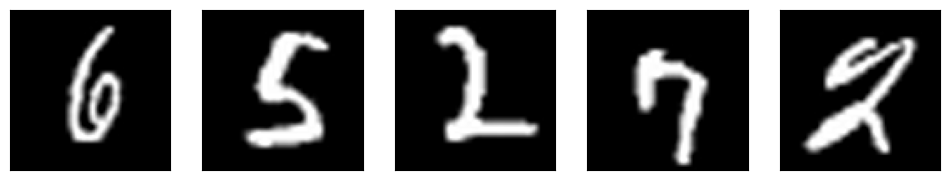

In [2]:
res = 96

data, targets = load_data("mnist.h5")
imgs = data[np.random.randint(0, 10_000, size=(5, ))] # a few random samples
imgs = imgs.transpose(1, 2, 0) # cv wants h,w,c, in this case c=batch

# resize to have some more pixels to work with
imgs = cv.resize(imgs, (res, res), interpolation=cv.INTER_CUBIC) 

multiplot(imgs)

#### cleanup

some digits contain veeery small specs of white. these should be removed. but the digits can be composed of multiple disjoint components themselves, so only keeping the largest one would be wrong. additionally, the images are also binarized

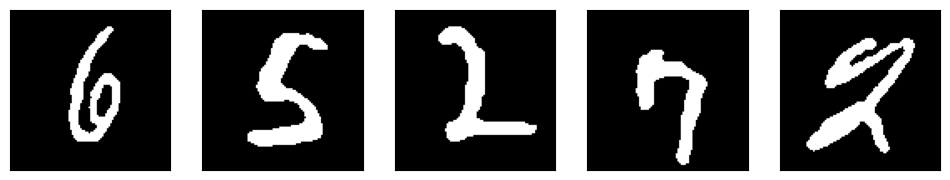

In [3]:
def clean_binarized(mask: np.ndarray, area_thresh: int) -> np.ndarray:
    # n = number of different connected componnets (background is always the first)
    # labels = basically a segmentation mask for the image; has the label number at each pixel (0 bg, 1,..., n blobs)
    # stats = ndarray, one row per label. [bb, bb, bb, bb, area]
    n, labels, stats, _ = cv.connectedComponentsWithStats(mask, connectivity=8)
    areas = stats[:, 4]
    
    # areas[labels]; numpy fancy indexing. returns the labels (img) with the respective area value placed at each pixel, corresponding to the label that was there. keep is a mask that only marks the large-blob-pixels. Areas is basically a lookup table for the mapping label -> area.
    keep = areas[labels] >= area_thresh
    
    return keep & mask

# define what a "small spec" is. about 3-5 pixels in the original mnist 28x28 -> scale to resolution used here
n_pixel_original = 4
scale = (res / 28) ** 2
small_thresh = int(n_pixel_original * scale)

# binarize and clean up
imgs_bin = np.where(imgs>127, 1, 0).astype(np.uint8)
imgs_bin_clean = np.stack([
    clean_binarized(imgs_bin[..., i], area_thresh = small_thresh) for i in range(imgs_bin.shape[-1])
], axis=-1)

multiplot(imgs_bin_clean)


## get a 2D SDF over the image

#### with morphological ops

this shows the basic idea well, but morphological ops with 3x3 kernels always shrink in a diamond pattern, so the sdf looks quite distorted

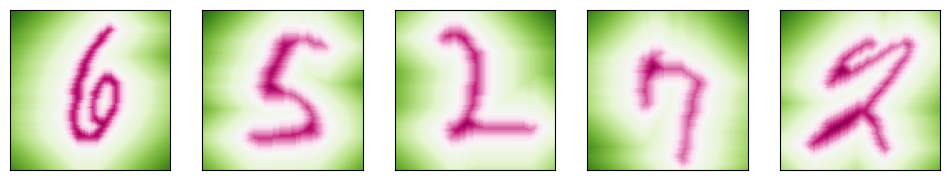

In [4]:
# signed distance field in 2d (distance from the character boundary)
sdf = np.zeros_like(imgs_bin_clean, dtype=np.int64)

# cross erosion kernel 
kernel = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0],
]).astype(np.uint8)

# inwards sdf part: eroding the binarized number step by step (always by 1 pixel) and adding whats left to the sdf. his way, the further from the boundary, the larger the sdf value gets
cpy = imgs_bin_clean.copy()
for i in range(100):
    sdf = sdf - cpy
    cpy = cv.erode(cpy, kernel, iterations=1)
    if cpy.sum() == 0: break
    
# same for the outside: inverting the mask, and eroding it
cpy = 1 - imgs_bin_clean.copy()
for i in range(100):
    sdf = sdf + cpy
    cpy = cv.erode(cpy, kernel, iterations=1)
    if cpy.sum() == 0: break

multiplot(sdf - 5, cmap="PiYG", center=0)

#### with scipy distance_transform_edt

this is the cleaner version that calculate the actual euclidean distance of each "foreground" (nonzero) pixel to the nearest "background" (zero) pixel. the sdf representation also facilitate easy "thickening" of the outline, by subtracting a constant value from the sdf

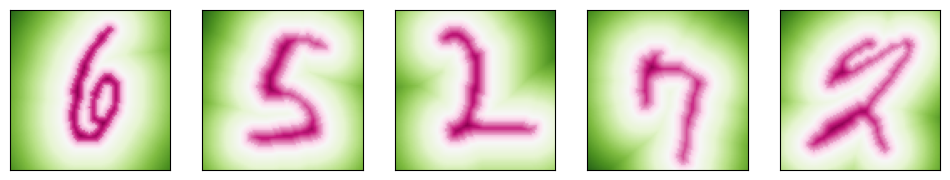

In [5]:
def edt(mask: np.ndarray) -> np.ndarray:
    out = ndimage.distance_transform_edt(mask)
    assert isinstance(out, np.ndarray)
    return out


sdf_inside = np.stack([
    edt(imgs_bin_clean[:, :, i]) for i in range(imgs_bin.shape[-1])
], axis=-1)

sdf_outside = np.stack([
    edt(1 - imgs_bin_clean[:, :, i]) for i in range(imgs_bin.shape[-1])
], axis=-1)

sdf = sdf_outside - sdf_inside # inside is defined as negative


multiplot(sdf - 5, cmap="PiYG", center=0)

## 3D SDF; from images to volume

#### get the skeletons of mnist

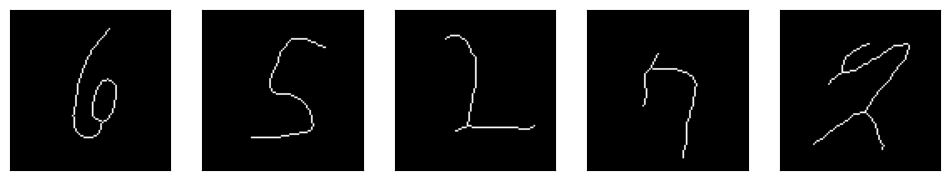

In [6]:
imgs_skeleton = np.stack([
    morphology.skeletonize(imgs_bin_clean[..., i]) for i in range(imgs_bin.shape[-1])
], axis=-1)


multiplot(imgs_skeleton, cmap="grey")

#### find the closest skeleton pixel for each pixel -> give each pixel the radius of its closest skeleton pixel

(to determine stroke thickness at each pixel)

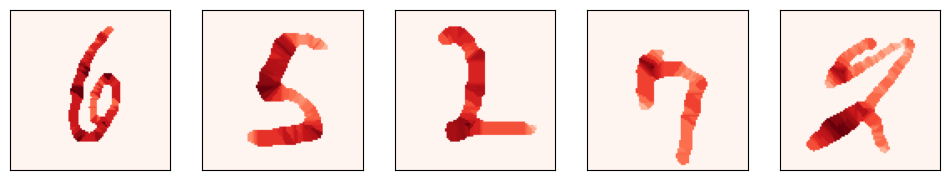

In [7]:
def assign_r_to_each_inside_pixel(imgs_skeleton, img_sdf):

    # this finds the closest skeleton pixel (index of skeleton pixel) for all pixels 
    _, indices = ndimage.distance_transform_edt(imgs_skeleton == 0, return_indices=True)

    # then, we can use the sdf as a radius-lookup table and assign a radius to each pixel (given by the closest skeleton sdf value, negative)
    radii = -img_sdf[indices[0], indices[1]]
    
    # this only makes sense on pixels inside the sdf
    return np.where(img_sdf < 0, radii, 0)

    
imgs_radii = np.stack([
    assign_r_to_each_inside_pixel(imgs_skeleton[..., i], sdf[..., i]) for i in range(imgs_bin.shape[-1])
], axis=-1) 

multiplot(imgs_radii, cmap="Reds")


#### "smooth" the radii a bit

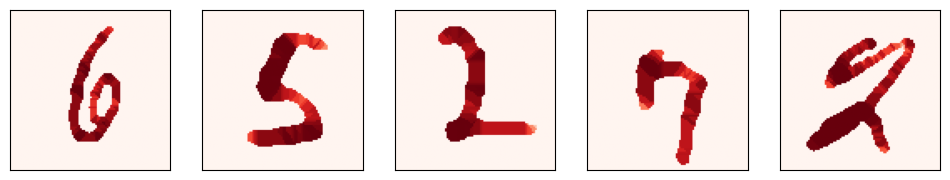

In [8]:
def smin_poly(a, b, k):
    h = np.clip(0.5 + 0.5 * (b - a) / k, a_min=0, a_max=1)
    return b * (1 - h) + a * h - k * h * (1 - h)

def smooth_radii(radii, skele):
    skele_radii = radii * skele
    r_typ = np.median(skele_radii[skele_radii > 0])
    
    smoothed_radii = smin_poly(
        a = radii, # value 1
        b = 1.0 * r_typ, # value 2
        k = 0.3 * r_typ  # spread
    )

    return smoothed_radii
    
imgs_radii = np.stack([
    smooth_radii(imgs_radii[..., i], imgs_skeleton[..., i]) for i in range(imgs_bin.shape[-1])
], axis=-1)

multiplot(imgs_radii, cmap="Reds")

#### find the "height-field"

-> a value at each pixel of the 2d image that represents how far it will be "extruded" in z direction

In [11]:
# now only do for one img
idx = 0

# compute the height values according to radius
R = imgs_radii[..., idx]
d = np.clip(-sdf[..., idx], a_min=0, a_max=R)

img_ztop = np.sqrt(R**2 - (R - d)**2)

I, J = np.indices((res, res))
go.Figure(
    data=go.Scatter3d(
        x = I.ravel(),
        y = J.ravel(),
        z = img_ztop.ravel()*3,
        mode = "markers",
        marker_size = 2,
    ),
    layout = dict(
        scene=dict(aspectmode="data"),
        margin=dict(l=10, r=10, t=10, b=10),
    )
).show()

#### build the actual SDF in 3d

In [15]:
nz = 20
z = np.arange(-nz, nz + 1, dtype=np.float32)
zz = z[None, None, :]

f = np.maximum(np.abs(zz) - img_ztop[:, :, None], sdf[..., idx][:, :, None])

from skimage.measure import marching_cubes
verts, faces, normals, _ = marching_cubes(f, level=0.0)

print(faces.shape)
go.Figure(
    data=go.Mesh3d(
        x = verts[:, 0],
        y = verts[:, 1],
        z = verts[:, 2],
        i = faces[:, 0],
        j = faces[:, 1],
        k = faces[:, 2],
        
    ),
    layout = dict(
        scene=dict(aspectmode="data"),
        margin=dict(l=10, r=10, t=10, b=10),
    )
)

(7620, 3)
